# Image Classification with a CNN (CIFAR-10)

**Goal:** train a small convolutional neural network (CNN) to recognize 10 kinds of pictures, then look at how well it does and where it makes mistakes.


## 1. Setup

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix

#fixed seed so results are repeatable
torch.manual_seed(42)
np.random.seed(42)

from google.colab import drive
drive.mount("/content/drive")
os.chdir("/content/drive/MyDrive")
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("PyTorch version:", torch.__version__)

Mounted at /content/drive
PyTorch version: 2.11.0+cpu


## 2. Load the data



In [2]:
classes = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_data = datasets.CIFAR10("data", train=True, download=True, transform=transform)
test_data = datasets.CIFAR10("data", train=False, download=True, transform=transform)

# A DataLoader hands the images to the model in small batches
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64)

print("Training images:", len(train_data))
print("Test images:", len(test_data))

Training images: 50000
Test images: 10000


## 3. Look at some images



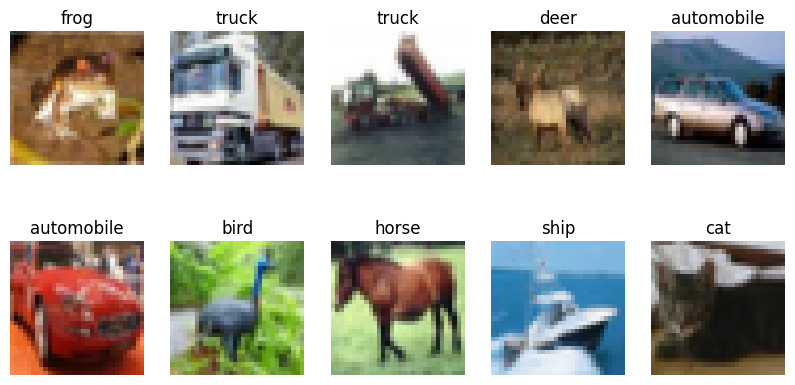

Images per category: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


In [3]:
def show_ready(image):
    image = image / 2 + 0.5                      # undo the normalization
    return image.permute(1, 2, 0).clamp(0, 1)    # channels last, as matplotlib expects

plt.figure(figsize=(10, 5))
for i in range(10):
    image, label = train_data[i]
    plt.subplot(2, 5, i + 1)
    plt.imshow(show_ready(image))
    plt.title(classes[label])
    plt.axis("off")
plt.show()

# CIFAR-10 is balanced: every category has the same number of training images
print("Images per category:", np.bincount(train_data.targets))

## 4. Build the CNN



In [4]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = SimpleCNN()
print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 5. Train the CNN



In [5]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 5

train_losses = []
train_accs = []
start = time.time()

for epoch in range(epochs):
    model.train()
    loss_sum, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)

    train_losses.append(loss_sum / len(train_loader))
    train_accs.append(100 * correct / total)
    print(f"Epoch {epoch+1}/{epochs}  loss={train_losses[-1]:.4f}  accuracy={train_accs[-1]:.2f}%")

training_minutes = (time.time() - start) / 60
print(f"Training time: {training_minutes:.2f} minutes")

Epoch 1/5  loss=1.3646  accuracy=50.88%
Epoch 2/5  loss=0.9868  accuracy=65.16%
Epoch 3/5  loss=0.8219  accuracy=71.15%
Epoch 4/5  loss=0.7093  accuracy=75.14%
Epoch 5/5  loss=0.6112  accuracy=78.56%
Training time: 8.29 minutes


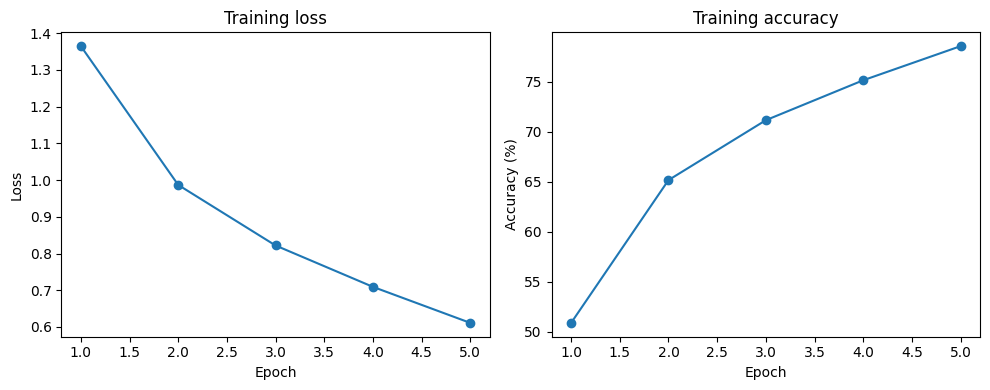

In [6]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training loss")

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), train_accs, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training accuracy")

plt.tight_layout()
plt.savefig("outputs/training_curves.png")
plt.show()

## 6. Test the model

The model never trained on the test images, so this shows how well it handles new pictures.

In [7]:
model.eval()
all_preds = []
all_labels = []
test_loss = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        test_loss += loss_fn(outputs, labels).item()
        all_preds.extend(outputs.argmax(1).tolist())
        all_labels.extend(labels.tolist())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

test_acc = 100 * np.mean(all_preds == all_labels)
test_loss = test_loss / len(test_loader)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.2f}%")
print(f"Last training accuracy: {train_accs[-1]:.2f}%")

Test loss: 0.8135
Test accuracy: 72.23%
Last training accuracy: 78.56%


## 7. Which categories are hard?

The confusion matrix counts how often each true category (rows) was predicted as each category (columns). The diagonal is correct predictions.

airplane      75.6%
automobile    80.4%
bird          60.2%
cat           57.2%
deer          66.3%
dog           57.3%
frog          82.0%
horse         77.4%
ship          88.4%
truck         77.5%


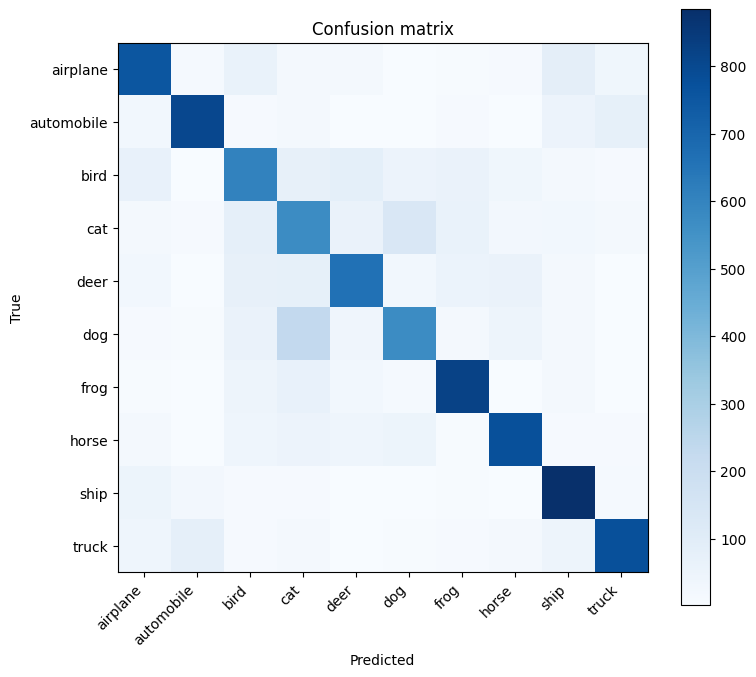

In [9]:
cm = confusion_matrix(all_labels, all_preds)

# Accuracy for each category = correct predictions / total images in that category
per_class_acc = 100 * cm.diagonal() / cm.sum(axis=1)
for name, acc in zip(classes, per_class_acc):
    print(f"{name:12s} {acc:5.1f}%")

plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(10), classes, rotation=45, ha="right")
plt.yticks(range(10), classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix")
plt.colorbar()
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png")
plt.show()

## 8. Look at mistakes

Incorrect predictions: 2777 out of 10000


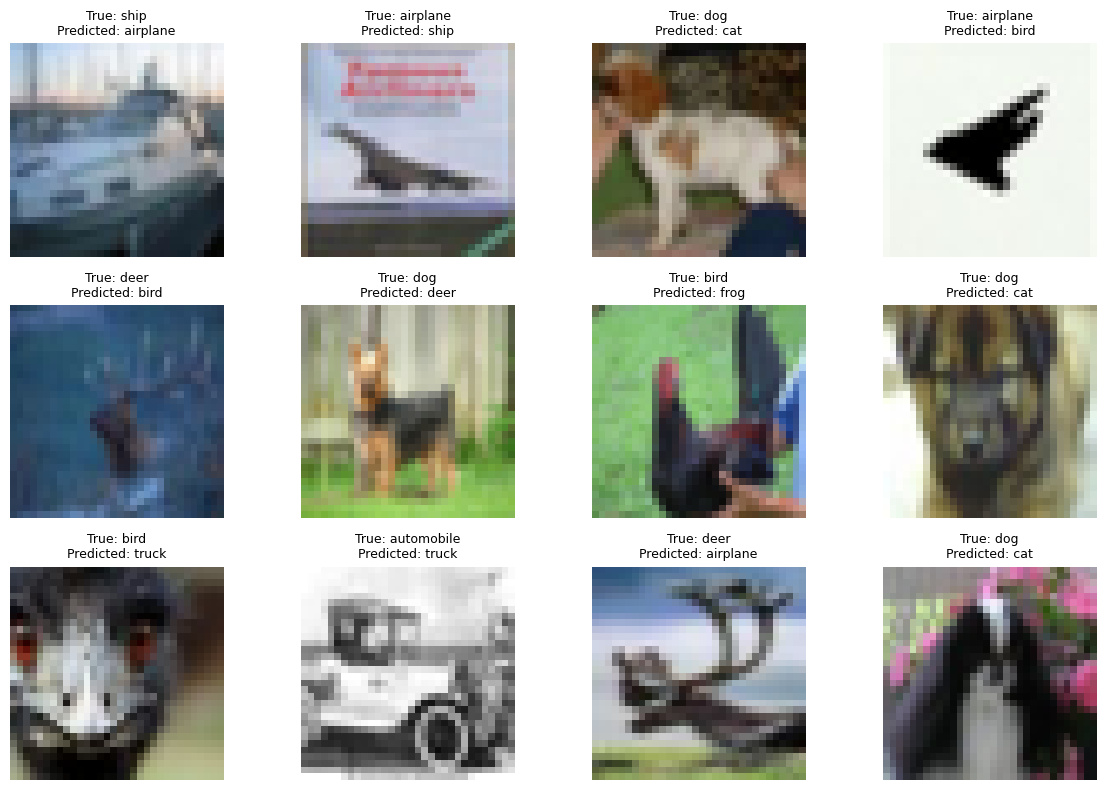

In [10]:
wrong = np.where(all_preds != all_labels)[0]
print("Incorrect predictions:", len(wrong), "out of", len(all_labels))

plt.figure(figsize=(12, 8))
for j, i in enumerate(wrong[:12]):
    image, true_label = test_data[i]
    plt.subplot(3, 4, j + 1)
    plt.imshow(show_ready(image))
    plt.title(f"True: {classes[true_label]}\nPredicted: {classes[all_preds[i]]}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.savefig("outputs/mistakes.png")
plt.show()